<a href="https://colab.research.google.com/github/vtu27065/Deep-Learning/blob/main/Task%208%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

In [2]:
data = np.sin(np.arange(0, 100, 0.5))

X, y = [], []
for i in range(len(data) - 10):
    X.append(data[i:i+10])
    y.append(data[i+10])

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: torch.Size([190, 10, 1])
Output shape: torch.Size([190, 1])


In [3]:
class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

model = LSTMModel()
print(model)

LSTMModel(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


In [4]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(100):
    output = model(X)
    loss = criterion(output, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("Training completed!")
print("Final Loss:", loss.item())

Training completed!
Final Loss: 8.575565516366623e-06


In [5]:
model.eval()

last_sequence = X[-1].unsqueeze(0)
future_predictions = []

with torch.no_grad():
    for _ in range(20):
        prediction = model(last_sequence)
        future_predictions.append(prediction.item())

        last_sequence = torch.cat(
            (last_sequence[:, 1:, :], prediction.unsqueeze(1)),
            dim=1
        )

print("Future Predictions:")
print(future_predictions)

Future Predictions:
[-0.8542836904525757, -0.5062763094902039, -0.034249044954776764, 0.4535692036151886, 0.8222158551216125, 0.9885457158088684, 0.9180653691291809, 0.6231207847595215, 0.1677483767271042, -0.32261335849761963, -0.7304107546806335, -0.9686022996902466, -0.9629725217819214, -0.720539927482605, -0.30868661403656006, 0.18548151850700378, 0.635323703289032, 0.9216867685317993, 0.9859538078308105, 0.8131800889968872]


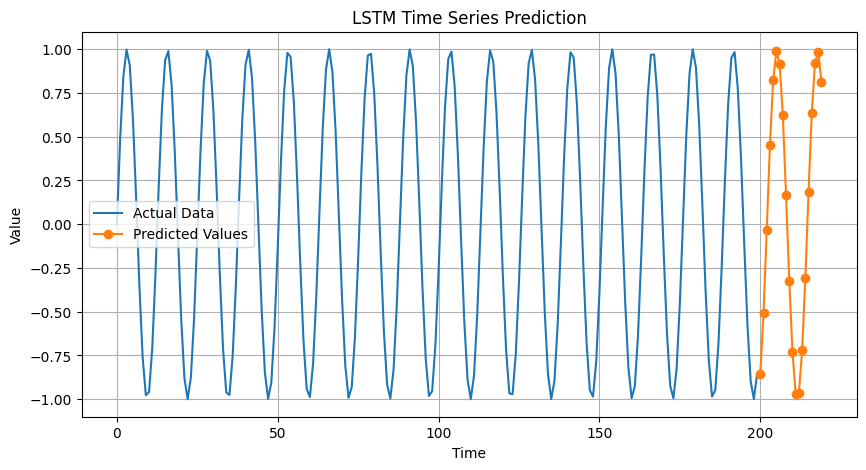

In [6]:
plt.figure(figsize=(10, 5))

plt.plot(data, label="Actual Data")
plt.plot(
    range(len(data), len(data) + 20),
    future_predictions,
    marker="o",
    label="Predicted Values"
)

plt.title("LSTM Time Series Prediction")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()